<a href="https://colab.research.google.com/github/Nayeem-294/CNN-Group09-Pneumonia-Detection/blob/main/CNN_Group09_Submission2_MobileNetV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Project - Submission 2: Pretrained model MobileNetV2, with and without fine-tuning
**Project:** Pneumonia Detection from Chest X-Ray Images Using Convolutional Neural Networks

**Group No:** 09

| Name | Student ID |
|---|---|
| Nayeem Ahmed | 2024-1-60-294 |
| Mahbuba Hoque Tabassum | 2023-2-60-030 |
| Sharmin Zaman Setu | 2023-3-60-476 |
| SM Erbajul Hasan | 2023-3-60-010 |

**This notebook:** MobileNetV2(ImageNet-pretrained) trained in two modes on the Kermany chest X-ray dataset:
1. **Without fine-tuning:** the pretrained part is frozen, only the new classifier head is trained.
2. **With fine-tuning:** the top 40% of the pretrained layers are also trained, with a small learning rate.

Each mode is trained for **40 epochs**. MobileNetV2 is used by Kundu et al. (2021) and Cha et al. (2021) in our related work.

Required results for each mode: accuracy curve, loss curve, classification report, confusion matrix on the test set, plus accuracy / precision / recall / F1 and training and testing time.



## 1. Setup

In [1]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "NO GPU found - use Runtime > Change runtime type > T4 GPU (CPU will be very slow)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os, sys, time, json, subprocess
from pathlib import Path

# Download the dataset from Kaggle (same as Submission 1). Skipped if it is already there.
if not Path("chest_xray_data").exists():
    from google.colab import files
    print("Upload your kaggle.json file:")
    up = files.upload()

    # Dynamically find the key in case Colab renamed the uploaded file (e.g., to 'kaggle (1).json')
    uploaded_filename = None
    for filename in up.keys():
        if "kaggle" in filename.lower() and filename.lower().endswith(".json"):
            uploaded_filename = filename
            break

    if not uploaded_filename:
         raise FileNotFoundError("Could not find a valid kaggle.json file in your uploads.")

    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    with open(os.path.expanduser("~/.kaggle/kaggle.json"), "wb") as f:
        f.write(up[uploaded_filename])
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "paultimothymooney/chest-xray-pneumonia",
                    "-p", "chest_xray_data", "--unzip"], check=True)

def find_root(base="chest_xray_data"):
    for p in Path(base).rglob("train"):
        if p.is_dir() and (p.parent / "test").is_dir() and "__MACOSX" not in str(p):
            return p.parent
    raise FileNotFoundError("Could not find train/test folders")

DATA_DIR = find_root()
print("Dataset root:", DATA_DIR)

Upload your kaggle.json file:


Saving kaggle (1).json to kaggle (1).json
Dataset root: chest_xray_data/chest_xray


In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, roc_auc_score)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# ---- Settings ----
MODEL_NAME = "MobileNetV2"
APP = tf.keras.applications.MobileNetV2
PREPROCESS = tf.keras.applications.mobilenet_v2.preprocess_input

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 40            # 40 epochs
VAL_FRACTION = 0.15    # validation taken from the train folder
WEIGHTS = "imagenet"
FT_FRACTION = 0.4      # share of the top layers that are unfrozen in the fine-tuning mode
LR_FROZEN = 1e-3
LR_FINETUNE = 1e-4
CLASSES = ["NORMAL", "PNEUMONIA"]   # label 0 = NORMAL, label 1 = PNEUMONIA (positive class)

tf.keras.utils.set_random_seed(SEED)

## 2. Data preparation
- The original `val` folder has only 16 images, so it is **not used**. We take a **stratified 15%** of the training images as the validation set.
- The original **test** folder (624 images) is used **only for the final evaluation**, never for tuning.
- Images are resized to 224x224 and converted to 3 channels (grayscale images are copied to RGB).
- **Class weights** handle the imbalance (about 3 PNEUMONIA images for every NORMAL image).
- **Augmentation** (training only): horizontal flip, small rotation, zoom, shift and brightness change.

In [4]:
def collect(split):
    paths, labels = [], []
    for li, c in enumerate(CLASSES):
        for p in sorted((DATA_DIR / split / c).rglob("*")):
            if p.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                paths.append(str(p)); labels.append(li)
    return np.array(paths), np.array(labels)

all_p, all_y = collect("train")
te_p, te_y = collect("test")
tr_p, va_p, tr_y, va_y = train_test_split(all_p, all_y, test_size=VAL_FRACTION,
                                          stratify=all_y, random_state=SEED)

summary = pd.DataFrame({s: {c: int((y == i).sum()) for i, c in enumerate(CLASSES)}
                        for s, y in [("train", tr_y), ("validation", va_y), ("test", te_y)]})
summary["total"] = summary.sum(axis=1)
summary.loc["TOTAL"] = summary.sum()
display(summary)

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=tr_y)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("Class weights:", {CLASSES[k]: round(v, 3) for k, v in class_weight.items()})

,train,validation,test,total
NORMAL,1140,201,234,1575
PNEUMONIA,3293,582,390,4265
TOTAL,4433,783,624,5840


Class weights: {'NORMAL': 1.944, 'PNEUMONIA': 0.673}


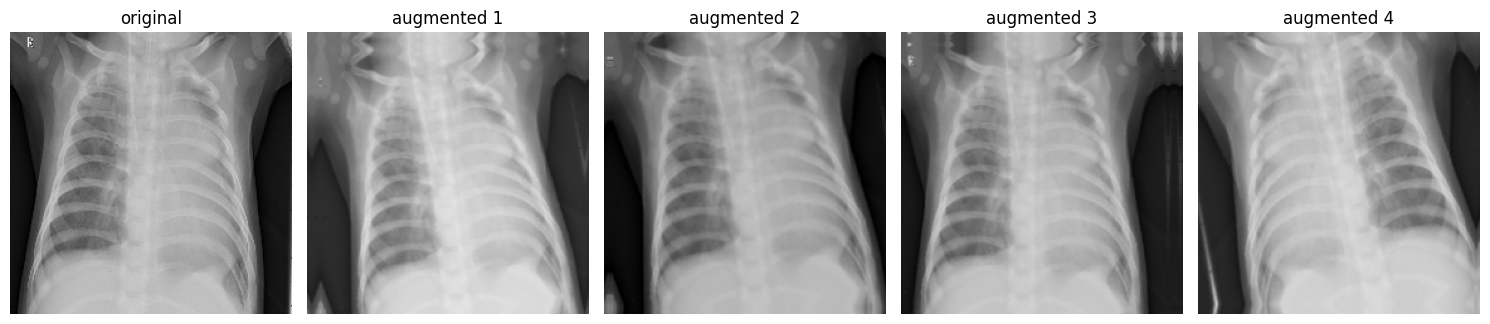

In [5]:
def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)          # grayscale -> 3 channels
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))     # pixel range stays 0-255 here
    return img, tf.expand_dims(tf.cast(label, tf.float32), -1)

def make_ds(p, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle:
        ds = ds.shuffle(len(p), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(tr_p, tr_y, True)
val_ds = make_ds(va_p, va_y, False)
test_ds = make_ds(te_p, te_y, False)

def make_augment():
    return models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),                 # about +-11 degrees
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomBrightness(0.1, value_range=(0, 255)),
    ], name="augmentation")

augment = make_augment()

# Show what augmentation does to one training image
img0, _ = next(iter(train_ds.unbatch().take(1)))
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(img0.numpy().astype("uint8")); axes[0].set_title("original")
for k in range(1, 5):
    axes[k].imshow(augment(tf.expand_dims(img0, 0), training=True)[0].numpy().astype("uint8"))
    axes[k].set_title(f"augmented {k}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Model
MobileNetV2 (ImageNet weights) + global average pooling + dropout 0.3 + one sigmoid unit.

- BatchNorm layers inside MobileNetV2 always stay in inference mode, which is the standard safe way to fine-tune.
- The same augmentation, class weights, optimiser (Adam) and 40 epochs are used in both modes, so the only difference is **frozen vs fine-tuned**.
- The weights of the **epoch with the lowest validation loss** are restored before testing (this guards against overfitting in the later epochs), and the learning rate is cut when the validation loss stops improving.

In [6]:
def build_model(finetune):
    base = APP(include_top=False, weights=WEIGHTS, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    if finetune:
        base.trainable = True
        n_unfreeze = int(len(base.layers) * FT_FRACTION)
        for l in base.layers[:-n_unfreeze]:
            l.trainable = False
        for l in base.layers[-n_unfreeze:]:
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False
        lr = LR_FINETUNE
    else:
        base.trainable = False
        lr = LR_FROZEN
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inputs)
    x = layers.Lambda(PREPROCESS, name="preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inputs, out, name=f"{MODEL_NAME}_{'finetuned' if finetune else 'frozen'}")
    model.compile(optimizer=Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    n_train = int(np.sum([np.prod(w.shape) for w in model.trainable_weights]))
    print(f"{model.name}: learning rate {lr}, trainable parameters {n_train:,}")
    return model

def run_mode(finetune):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(finetune)
    tag = "finetuned" if finetune else "frozen"
    ckpt = f"best_{MODEL_NAME}_{tag}.weights.h5"
    cbs = [ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True),
           ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                     class_weight=class_weight, callbacks=cbs, verbose=2)
    train_time = time.time() - t0
    model.load_weights(ckpt)                      # best validation epoch
    model.predict(test_ds.take(1), verbose=0)     # warm-up so test time is not distorted
    t0 = time.time()
    probs = model.predict(test_ds, verbose=0).ravel()
    test_time = time.time() - t0
    return hist.history, probs, train_time, test_time

def report(title, history, probs, train_time, test_time):
    y_true = te_y
    y_pred = (probs >= 0.5).astype(int)
    epochs = range(1, len(history["loss"]) + 1)
    best = int(np.argmin(history["val_loss"]))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(epochs, history["accuracy"], label="train")
    ax[0].plot(epochs, history["val_accuracy"], label="validation")
    ax[0].axvline(best + 1, ls="--", color="grey", label=f"best epoch ({best + 1})")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].legend()
    ax[1].plot(epochs, history["loss"], label="train")
    ax[1].plot(epochs, history["val_loss"], label="validation")
    ax[1].axvline(best + 1, ls="--", color="grey", label=f"best epoch ({best + 1})")
    ax[1].set_title(f"{title}: loss"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].legend()
    plt.tight_layout(); plt.show()

    print(f"Classification report - {title} (test set, {len(y_true)} images)")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.6, 4))
    plt.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    plt.xticks([0, 1], CLASSES); plt.yticks([0, 1], CLASSES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix - {title}")
    plt.tight_layout(); plt.show()

    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1)
    tr_acc, va_acc = history["accuracy"][best], history["val_accuracy"][best]
    gap = tr_acc - va_acc
    if gap > 0.05:
        diag = f"possible OVERFITTING (train accuracy {tr_acc:.3f} is {gap:.3f} above validation {va_acc:.3f})"
    elif tr_acc < 0.85 and va_acc < 0.85:
        diag = f"possible UNDERFITTING (train {tr_acc:.3f}, validation {va_acc:.3f} are both low)"
    else:
        diag = f"no strong sign of over- or underfitting (train {tr_acc:.3f}, validation {va_acc:.3f})"
    print("Fit check at the best epoch:", diag)
    print(f"Training time: {train_time:.1f} s ({train_time / 60:.1f} min) | Testing time: {test_time:.2f} s")

    return dict(model=MODEL_NAME, mode=title, epochs_run=len(epochs), best_epoch=best + 1,
                train_acc=round(tr_acc, 4), val_acc=round(va_acc, 4),
                test_accuracy=round(accuracy_score(y_true, y_pred), 4),
                precision=round(p, 4), recall=round(r, 4), f1=round(f, 4),
                auc=round(roc_auc_score(y_true, probs), 4),
                train_time_s=round(train_time, 1), test_time_s=round(test_time, 2))

## 4. Mode A: MobileNetV2 WITHOUT fine-tuning
All pretrained layers are frozen. Only the new classifier head is trained (learning rate 1e-3).

In [7]:
hist_a, probs_a, tt_a, ts_a = run_mode(finetune=False)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2_frozen: learning rate 0.001, trainable parameters 1,281
Epoch 1/40
139/139 - 63s - 455ms/step - accuracy: 0.8374 - loss: 0.3686 - val_accuracy: 0.9438 - val_loss: 0.1894 - learning_rate: 0.0010
Epoch 2/40
139/139 - 35s - 249ms/step - accuracy: 0.9125 - loss: 0.2147 - val_accuracy: 0.9489 - val_loss: 0.1565 - learning_rate: 0.0010
Epoch 3/40
139/139 - 33s - 234ms/step - accuracy: 0.9217 - loss: 0.1888 - val_accuracy: 0.9566 - val_loss: 0.1298 - learning_rate: 0.0010
Epoch 4/40
139/139 - 37s - 268ms/step - accuracy: 0.9314 - loss: 0.1668 - val_accuracy: 0.9527 - val_loss: 0.1359 - learning_rate: 0.0010
Epoch 5/40
139/139 - 32s - 233ms/step - accuracy: 0.9355 - loss: 0.1558 - val_accuracy: 0.9527 - val_loss: 0.1225 - learning_rate: 0.0010
Epoch 6/40
139/139 - 33s - 236ms/step - accuracy: 0.9395 - loss: 0.1485 - val_accuracy: 0.9527 - val_loss: 0.1261 - learning_rate: 0.0010
Epoch 7/40
139/139 - 32s - 230ms/step - accuracy: 0.939

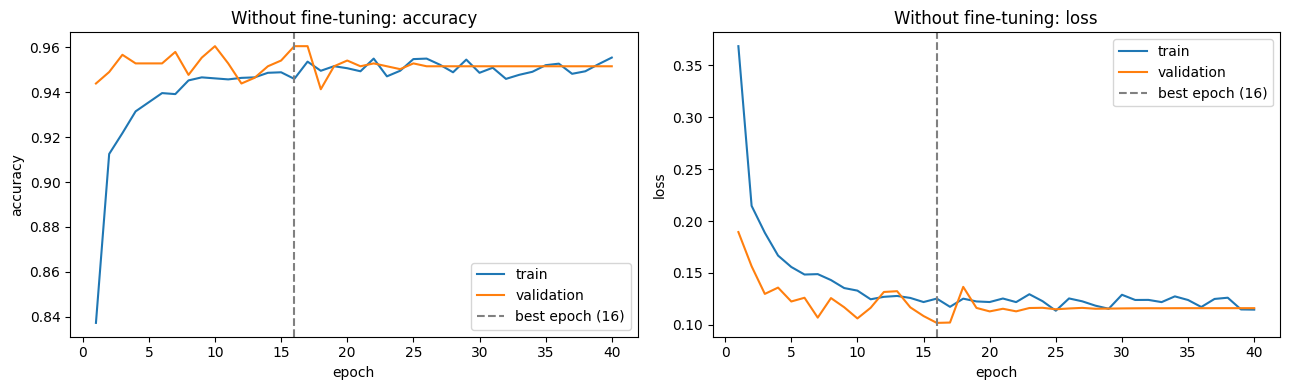

Classification report - Without fine-tuning (test set, 624 images)
              precision    recall  f1-score   support

      NORMAL     0.9605    0.6239    0.7565       234
   PNEUMONIA     0.8136    0.9846    0.8910       390

    accuracy                         0.8494       624
   macro avg     0.8870    0.8043    0.8237       624
weighted avg     0.8687    0.8494    0.8405       624



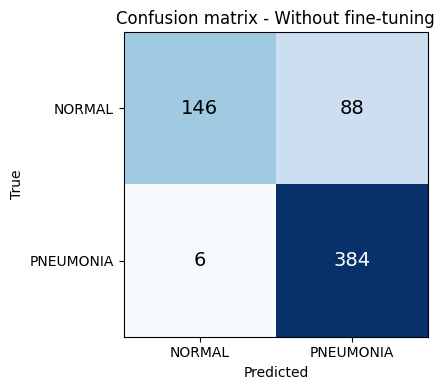

Fit check at the best epoch: no strong sign of over- or underfitting (train 0.946, validation 0.960)
Training time: 1500.0 s (25.0 min) | Testing time: 6.52 s


In [8]:
res_a = report("Without fine-tuning", hist_a, probs_a, tt_a, ts_a)

## 5. Mode B: MobileNetV2 WITH fine-tuning
The top 40% of the MobileNetV2 layers (except BatchNorm) are unfrozen and trained together with the head, using a small learning rate (1e-4).



In [9]:
hist_b, probs_b, tt_b, ts_b = run_mode(finetune=True)

MobileNetV2_finetuned: learning rate 0.0001, trainable parameters 1,936,513
Epoch 1/40
139/139 - 45s - 324ms/step - accuracy: 0.9035 - loss: 0.2263 - val_accuracy: 0.9566 - val_loss: 0.1056 - learning_rate: 1.0000e-04
Epoch 2/40
139/139 - 37s - 263ms/step - accuracy: 0.9522 - loss: 0.1176 - val_accuracy: 0.9055 - val_loss: 0.2553 - learning_rate: 1.0000e-04
Epoch 3/40
139/139 - 35s - 251ms/step - accuracy: 0.9562 - loss: 0.1105 - val_accuracy: 0.9579 - val_loss: 0.0965 - learning_rate: 1.0000e-04
Epoch 4/40
139/139 - 34s - 242ms/step - accuracy: 0.9725 - loss: 0.0749 - val_accuracy: 0.9387 - val_loss: 0.1224 - learning_rate: 1.0000e-04
Epoch 5/40
139/139 - 35s - 253ms/step - accuracy: 0.9729 - loss: 0.0652 - val_accuracy: 0.9796 - val_loss: 0.0635 - learning_rate: 1.0000e-04
Epoch 6/40
139/139 - 39s - 281ms/step - accuracy: 0.9723 - loss: 0.0706 - val_accuracy: 0.9400 - val_loss: 0.1546 - learning_rate: 1.0000e-04
Epoch 7/40
139/139 - 42s - 299ms/step - accuracy: 0.9795 - loss: 0.0516 

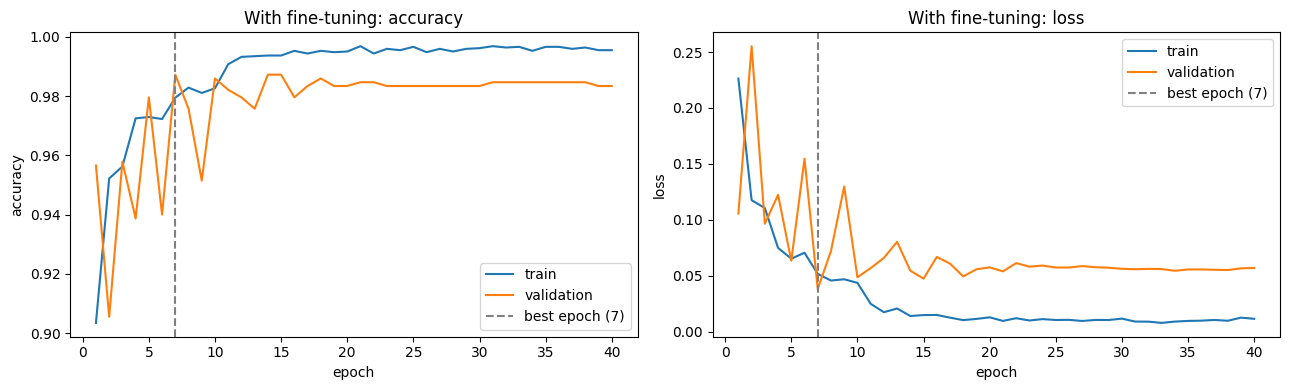

Classification report - With fine-tuning (test set, 624 images)
              precision    recall  f1-score   support

      NORMAL     0.9917    0.5128    0.6761       234
   PNEUMONIA     0.7734    0.9974    0.8712       390

    accuracy                         0.8157       624
   macro avg     0.8825    0.7551    0.7736       624
weighted avg     0.8553    0.8157    0.7980       624



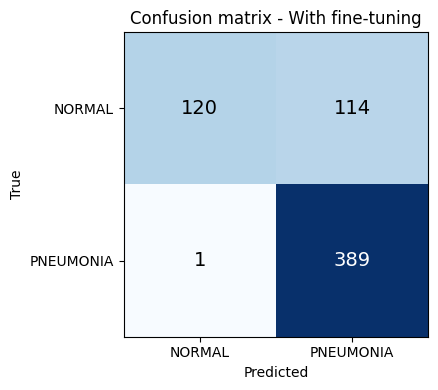

Fit check at the best epoch: no strong sign of over- or underfitting (train 0.979, validation 0.987)
Training time: 1466.4 s (24.4 min) | Testing time: 4.35 s


In [10]:
res_b = report("With fine-tuning", hist_b, probs_b, tt_b, ts_b)

## 6. Summary of both modes

mode,Without fine-tuning,With fine-tuning
model,MobileNetV2,MobileNetV2
epochs_run,40,40
best_epoch,16,7
train_acc,0.9459,0.9795
val_acc,0.9604,0.9872
test_accuracy,0.8494,0.8157
precision,0.8136,0.7734
recall,0.9846,0.9974
f1,0.891,0.8712
auc,0.9657,0.9727


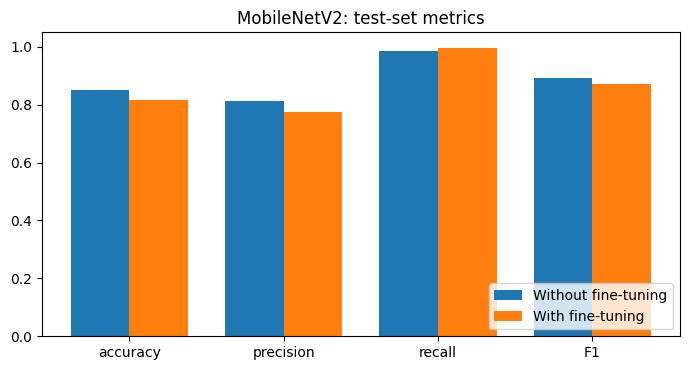

In [11]:
results = pd.DataFrame([res_a, res_b]).set_index("mode")
display(results.T)
results.to_csv(f"results_{MODEL_NAME}.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
metrics = ["test_accuracy", "precision", "recall", "f1"]
x = np.arange(len(metrics)); w = 0.38
ax.bar(x - w / 2, results.loc["Without fine-tuning", metrics], w, label="Without fine-tuning")
ax.bar(x + w / 2, results.loc["With fine-tuning", metrics], w, label="With fine-tuning")
ax.set_xticks(x); ax.set_xticklabels(["accuracy", "precision", "recall", "F1"])
ax.set_ylim(0, 1.05); ax.set_title(f"{MODEL_NAME}: test-set metrics"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### How overfitting and underfitting were handled
- **Dropout (0.3)** before the output layer and **data augmentation** during training.
- **Class weights**, so the model does not just predict the majority class (PNEUMONIA).
- **Best-epoch checkpoint:** the weights with the lowest validation loss are restored, so extra epochs that overfit do not hurt the test result.
- **Learning-rate reduction** when the validation loss stops improving.
- **Small learning rate (1e-4) and frozen BatchNorm** in the fine-tuning mode, so the pretrained features are not destroyed.
- The **fit check** printed after each mode compares train and validation accuracy at the best epoch.

## Observations

**Epochs used:** 40 for both modes.

**Better mode:** On the test set, the model **without fine-tuning** performed better overall: accuracy 0.8494 vs 0.8157, precision 0.8136 vs 0.7734 and F1 0.8910 vs 0.8712. The fine-tuned model had slightly higher recall (0.9974 vs 0.9846) and a higher AUC (0.9727 vs 0.9657).

**Effect of fine-tuning:** Fine-tuning raised the validation accuracy (0.9872 vs 0.9604) and the AUC, but it did **not** improve the test accuracy or F1. On the test set the fine-tuned model predicted PNEUMONIA too often: it found 389 of 390 pneumonia cases but recognised only 120 of 234 NORMAL images (NORMAL recall 0.5128, compared with 146 of 234, or 0.6239, without fine-tuning). Fine-tuning took about the same training time as the frozen model.

**Overfitting / underfitting:** At the best epoch, train and validation accuracy were 0.9459 and 0.9604 in Mode A (best epoch 16), and 0.9795 and 0.9872 in Mode B (best epoch 7). Validation accuracy was not lower than training accuracy in either mode, so the fit check found no strong sign of overfitting or underfitting. In Mode B the training loss kept falling after epoch 10 (to about 0.01) while the validation loss stayed near 0.055, so the later epochs fit the training data more closely; restoring the weights of the best epoch avoids this. As with DenseNet121, there is a large drop from validation accuracy (0.96 and 0.99) to test accuracy (0.85 and 0.82). Our validation set is taken from the same folder as the training images, while the official test set is separate. Possible reasons are a difference between the training and test images, or images of the same patient appearing in both our training and validation parts, which would make the validation score too optimistic. We did not check which reason applies.

**Errors:** In Mode A the confusion matrix shows 88 NORMAL images wrongly predicted as PNEUMONIA (false positives) and 6 PNEUMONIA images missed (false negatives). In Mode B there are 114 false positives and 1 false negative. Both modes mostly make false alarms (NORMAL predicted as PNEUMONIA), but Mode A makes fewer of them, while Mode B misses almost no pneumonia cases.

**Time:** Training took 1500.0 s (25.0 min) in Mode A and 1466.4 s (24.4 min) in Mode B. Testing took 6.52 s and 4.35 s. The two modes use the same network for prediction, so the testing-time difference is probably timing noise, not a real difference.

**Comparison with DenseNet121:** MobileNetV2 reached a higher test accuracy and F1 than DenseNet121 in both modes (without fine-tuning: 0.8494 and 0.8910 vs 0.8221 and 0.8714; with fine-tuning: 0.8157 and 0.8712 vs 0.7676 and 0.8429), even though it is a much smaller network. Training time was almost the same (about 25 min vs 26 min per mode), which may suggest that much of the time went into reading and resizing the images, not into the network itself.

## References
Dataset: D. S. Kermany et al., *Cell*, 2018 (Kaggle: paultimothymooney/chest-xray-pneumonia). Pretrained weights: ImageNet, via `tf.keras.applications`.